In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scripts import *

p = Path('genai_results_new/vlm_image_gen')
dfs = {}
for f in p.iterdir():
    if 'single' in str(f):
        dfs[str(f)] = pd.read_csv(f, nrows=9)

# INT8

In [2]:
cpu = prepare_benchmark(dfs['genai_results_new/vlm_image_gen/sd_cpu_int8_single.csv'])
gpu = prepare_benchmark(dfs['genai_results_new/vlm_image_gen/sd_gpu_int8_single.csv'])

int8 = {
    "cpu": cpu,
    "gpu": gpu,
}

data_int8 = pd.concat(
    [prepare_benchmark(df).assign(source=name)
     for name, df in int8.items()],
    ignore_index=True,
)


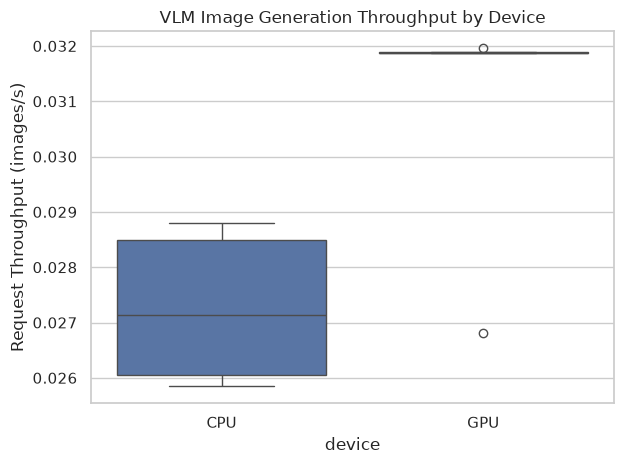

In [36]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = data_int8.copy()

df_plot["start"] = pd.to_datetime(df_plot["start"])
df_plot["end"] = pd.to_datetime(df_plot["end"])

df_plot["request_time_sec"] = (
    df_plot["end"] - df_plot["start"]
).dt.total_seconds()

df_plot["request_throughput"] = (
    1 / df_plot["request_time_sec"]
)

sns.boxplot(
    data=df_plot,
    x="device",
    y="request_throughput",
    hue="device",
    legend=False
)

plt.ylabel("Request Throughput (images/s)")
plt.title("VLM Image Generation Throughput by Device")
plt.tight_layout()
plt.show()


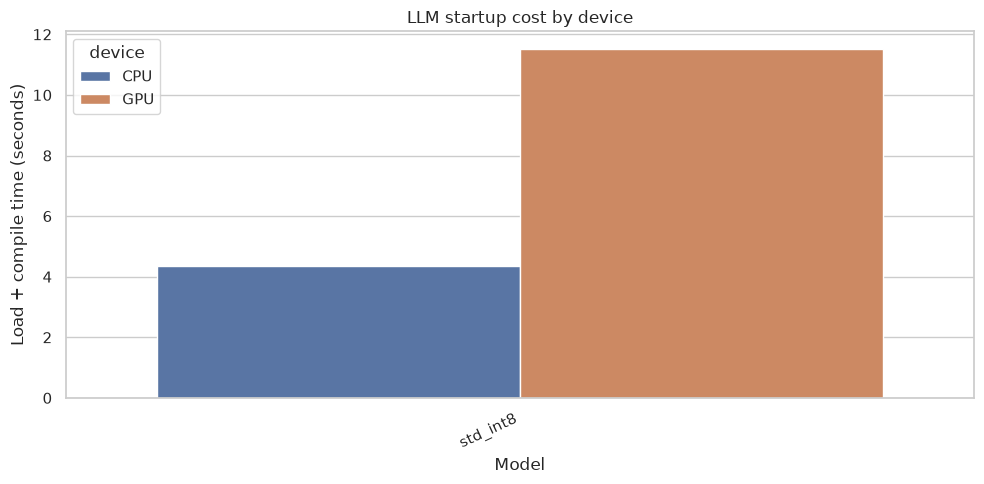

In [12]:
plot_startup_cost(int8)

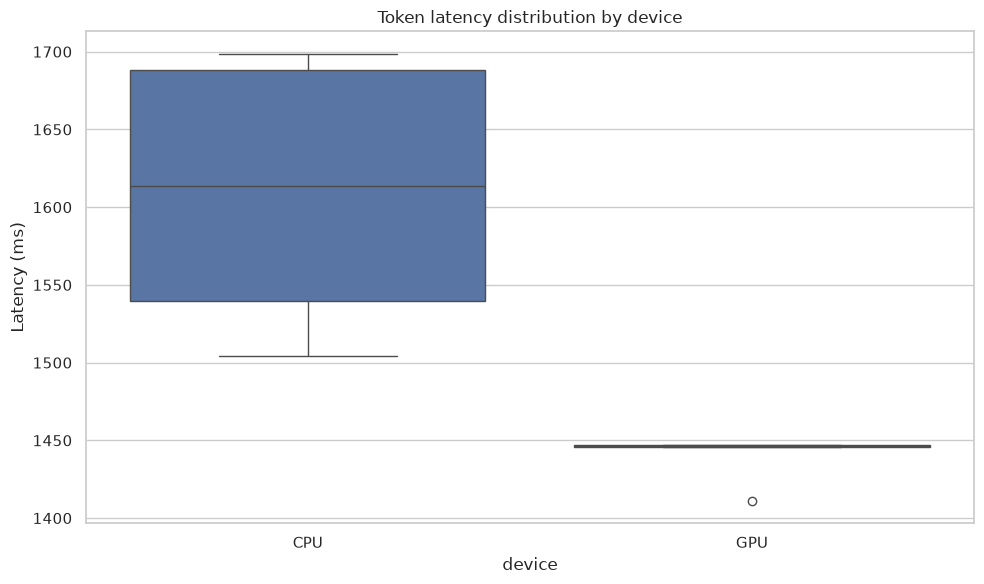

In [33]:
def plot_latency(data):
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=data,
        x="device",
        y="2nd_avg_latency(ms)", 
        hue="device",
        legend=False,
    )
    plt.ylabel("Latency (ms)")
    plt.title("Token latency distribution by device")
    plt.tight_layout()
    plt.show()

plot_latency(data_int8)


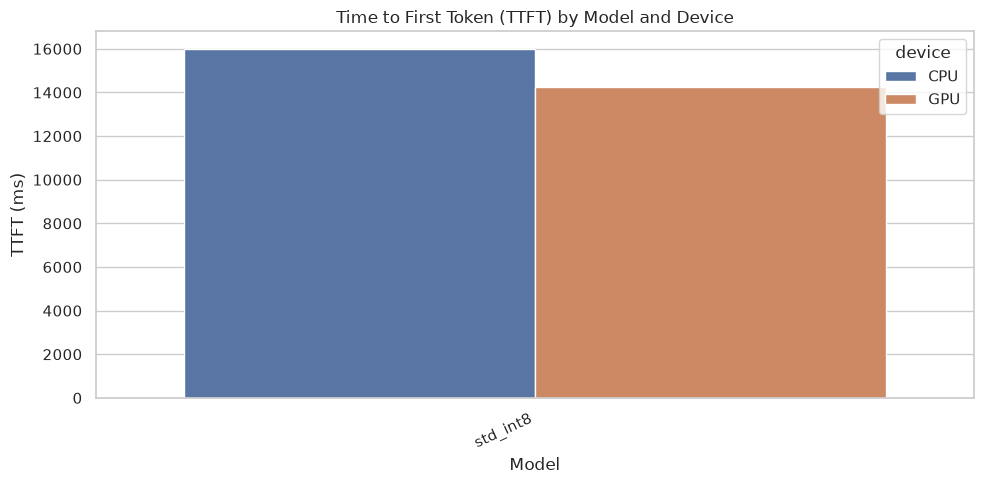

In [14]:
plot_ttft(int8)

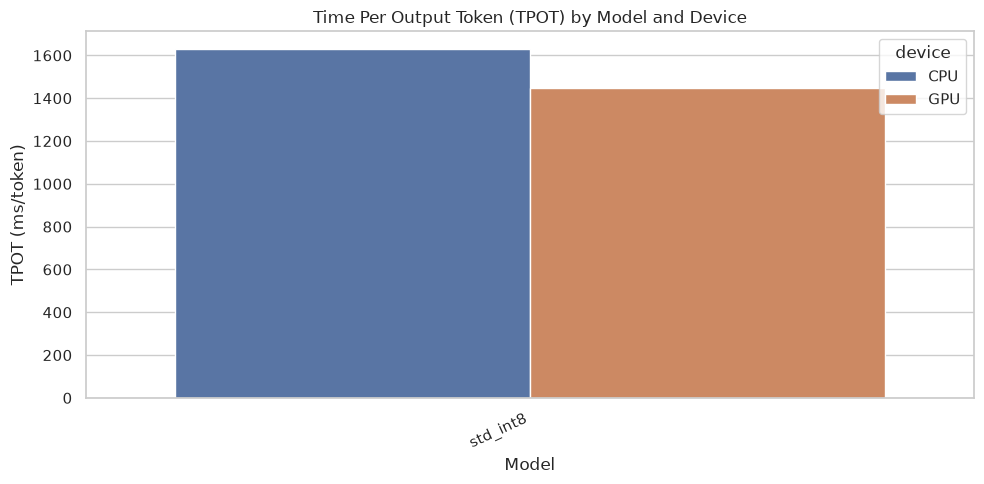

In [16]:
plot_tpot(int8)

# FP16

In [37]:
cpu = prepare_benchmark(dfs['genai_results_new/vlm_image_gen/sd_cpu_fp16_single.csv'])
gpu = prepare_benchmark(dfs['genai_results_new/vlm_image_gen/sd_gpu_fp16_single.csv'])

fp16 = {
    "cpu": cpu,
    "gpu": gpu,
}

data_fp16 = pd.concat(
    [prepare_benchmark(df).assign(source=name)
     for name, df in fp16.items()],
    ignore_index=True,
)


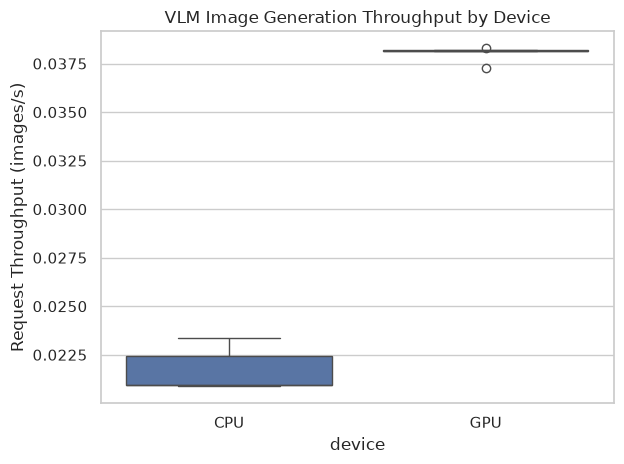

In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = data_fp16.copy()

df_plot["start"] = pd.to_datetime(df_plot["start"])
df_plot["end"] = pd.to_datetime(df_plot["end"])

df_plot["request_time_sec"] = (
    df_plot["end"] - df_plot["start"]
).dt.total_seconds()

df_plot["request_throughput"] = (
    1 / df_plot["request_time_sec"]
)

sns.boxplot(
    data=df_plot,
    x="device",
    y="request_throughput",
    hue="device",
    legend=False
)

plt.ylabel("Request Throughput (images/s)")
plt.title("VLM Image Generation Throughput by Device")
plt.tight_layout()
plt.show()


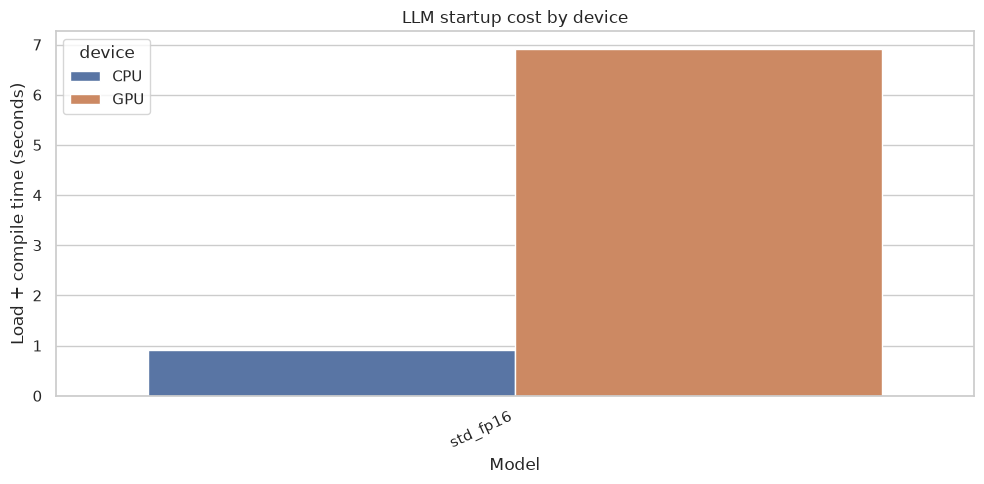

In [39]:
plot_startup_cost(fp16)

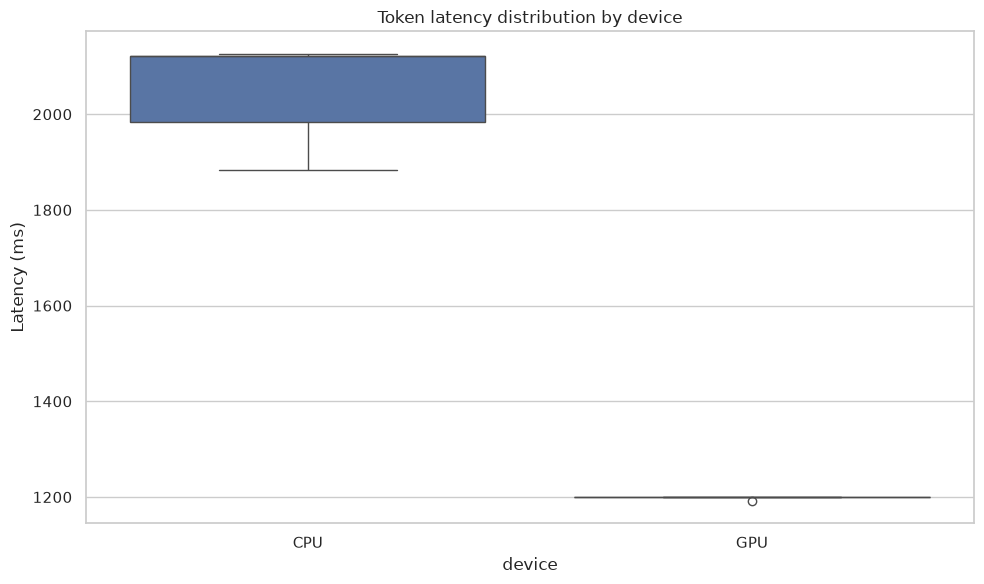

In [40]:
def plot_latency(data):
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=data,
        x="device",
        y="2nd_avg_latency(ms)", 
        hue="device",
        legend=False,
    )
    plt.ylabel("Latency (ms)")
    plt.title("Token latency distribution by device")
    plt.tight_layout()
    plt.show()

plot_latency(data_fp16)


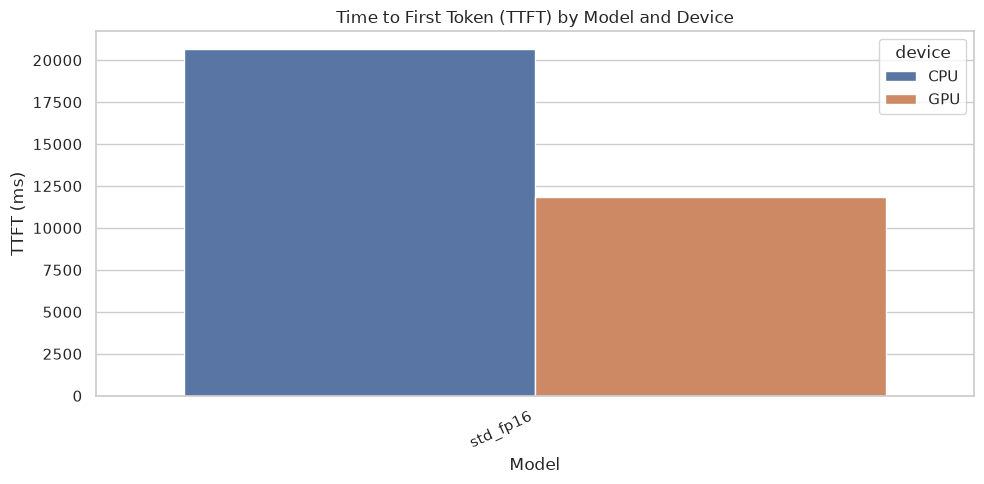

In [41]:
plot_ttft(fp16)

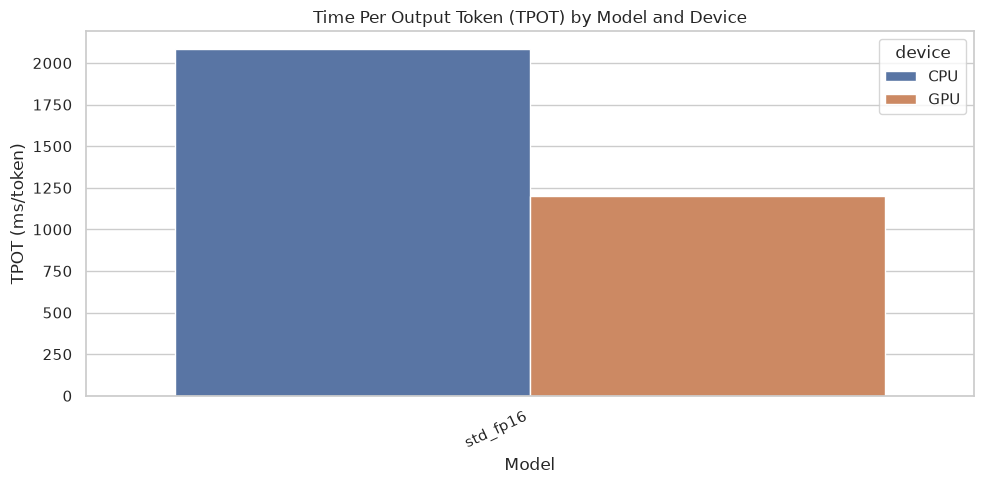

In [42]:
plot_tpot(fp16)